# ２章　マルコフ決定過程
## 『ゼロから作る Deep Learning ❹』2.1〜2.2 輪読会

第 1 章では、スロットマシンを選び、その場で得られる報酬から各行動の価値を推定した。第 2 章では、**行動によって次の状況が変わる問題**を扱う。今の行動は、今回の報酬だけでなく、次に選べる行動や将来の報酬にも影響する。

今回は、その仕組みをマルコフ決定過程（Markov decision process; MDP）として表す。グリッドワールドを例に、状態・行動・報酬を区別し、環境を表す状態遷移と報酬関数、エージェントを表す方策を、数式と小さな実験で確かめる。

### 目次

| Section | Contents |
|---|---|
| 0. 実行環境と記号 | 状態・行動・報酬と時刻の対応 |
| 2.1.1 MDPの具体例 | バンディットとの違いとグリッドワールド |
| 2.1.2 エージェントと環境のやりとり | 1 ステップで何が起きるか |
| 2.2.1 状態遷移 | マルコフ性、決定的・確率的な遷移 |
| 2.2.2 報酬関数 | 遷移に対する報酬と、その期待値 |
| 2.2.3 エージェントの方策 | 決定的・確率的な行動選択 |
| 振り返り | まとめと確認問題 |
| Appendix | 方策と状態遷移を組み合わせた 1 ステップ |

節番号と節名は[出版社の公開目次](https://www.oreilly.co.jp/books/9784873119755/)に対応する。解説・図・数値実験は輪読用に構成したものなので、書籍と併せて読む。

グリッドの配置と基本的な移動・報酬のルールは [`common/gridworld.py`](../common/gridworld.py) を参照する。確率的に進行方向がずれる例は、この資料で追加した実験である。収益・状態価値・最適方策の定義は 2.3 以降で扱う。

## 0. 実行環境と記号

必要なライブラリは NumPy・pandas・Matplotlib である。セルを上から順に実行する。他の Notebook の変数や外部データは使わない。

リポジトリのルートから、次のコマンドで起動できる。

```bash
uv run --extra notebooks jupyter lab my_notebooks
```

乱数を使うセルでは生成器を作り直し、再実行しても同じ結果になるようにする。グラフ内のラベルは、日本語フォントに依存しないよう英語で表示する。

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

SEED = 20261031
COLORS = ["#137C83", "#D97732", "#7455A4", "#456A9C"]
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    # Notebook の表示幅でも、目盛りや添字が読みやすいサイズにする。
    "axes.grid": True, "grid.alpha": 0.18, "font.size": 20,
    "axes.titlesize": 22, "axes.titlepad": 18, "axes.labelsize": 20,
    "xtick.labelsize": 20, "ytick.labelsize": 20, "legend.fontsize": 18,
    "axes.prop_cycle": matplotlib.cycler(color=COLORS),
})
print("Python", sys.version.split()[0])
print("NumPy", np.__version__, "pandas", pd.__version__,
      "Matplotlib", matplotlib.__version__)

Python 3.11.15
NumPy 1.23.5 pandas 2.3.3 Matplotlib 3.10.9


### 状態・行動・報酬を区別する

| 記号 | 意味 | この資料のコード |
|---|---|---|
| $t$ | 行動する時刻。0 から数える | `t` |
| $S_t$、$s$ | 状態を表す確率変数と、その具体的な値 | `state`：`(行, 列)` |
| $A_t$、$a$ | 行動を表す確率変数と、その具体的な値 | `action`：上下左右の番号 |
| $R_t$、$r_t$ | 行動 $A_t$ の結果として得る報酬と、その実現値 | `reward` |
| $S_{t+1}$、$s'$ | 行動した後の状態 | `next_state` |
| $p(s'\mid s,a)$ | 状態 $s$ で行動 $a$ を選んだときの、次状態の確率 | `transition_probs(s, a)` |
| $r(s,a,s')$ | その遷移で得る報酬 | `reward(s, a, s_next)` |
| $\pi(a\mid s)$ | 状態 $s$ で行動 $a$ を選ぶ確率 | 方策の確率配列 |

この資料では **$S_t \rightarrow A_t \rightarrow (R_t,S_{t+1})$** の順にやりとりする。行動の結果を $R_{t+1}$ と書く文献もあるが、添字の約束が異なる。ここでは途中で混ぜない。

小文字の $r_t$ は観測した 1 個の数値、$r(s,a,s')$ は報酬を決める関数である。また、前章の真の行動価値 $q(a)$ や推定値 $Q(a)$ とも区別する。

# 2.1 MDPとは

バンディットでは「どの腕を選ぶか」が中心だった。MDP では、**今どの状態にいるかによって、行動の結果が変わる**。

| 観点 | 第 1 章のバンディット | 今回のグリッドワールド |
|---|---|---|
| 状態 | 行動による状態遷移を扱わない | 現在いるマス |
| 行動 | 腕を選ぶ | 上下左右へ移動する |
| 行動の結果 | その腕から報酬を受け取る | 次のマスへ移り、報酬を受け取る |
| 後の選択への影響 | 台の配置や選べる腕は変わらない | 移動先によって、次に進める場所が変わる |

非定常バンディットでは勝率が時間とともに変わったが、それだけで「行動が次の状態を変える仕組み」をモデル化したわけではない。今回のグリッドは移動規則が固定されていても、行動によって状態が変わる。

## 2.1.1 MDPの具体例

3 行 × 4 列のマス目を考える。エージェントは左下の `Start` から、右上の `Goal` を目指す。

- **状態**は現在位置 `(行, 列)`。左上を `(0, 0)` とし、壁以外の 11 マスを考える。
- **行動**は `UP=0`、`DOWN=1`、`LEFT=2`、`RIGHT=3`。
- まずは選んだ方向へ必ず 1 マス進む。盤面の外や壁へ向かう行動では、現在のマスにとどまる。
- **報酬**は移動先で決まり、ゴールなら $+1$、`Penalty` のマスなら $-1$、それ以外は $0$。
- ゴールに着いたら、その試行を終了する。`Penalty` は終了マスではない。

通常の移動では報酬が 0 でも、ゴールに近づく意味がある。その場の報酬だけでは、行動のよさを十分に判断できない。

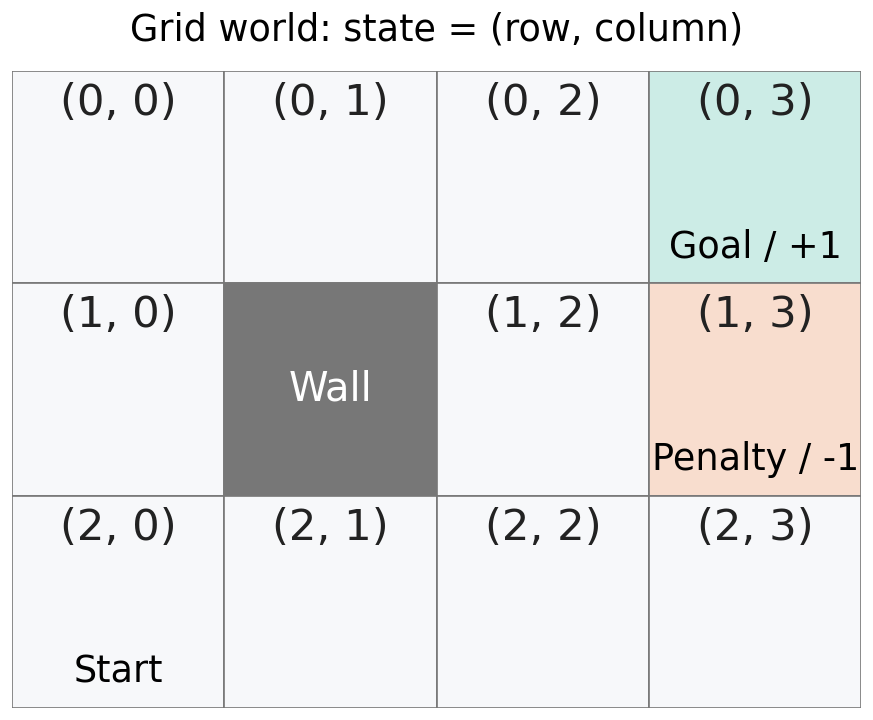

In [2]:
HEIGHT, WIDTH = 3, 4
START, GOAL, WALL, PENALTY = (2, 0), (0, 3), (1, 1), (1, 3)
ACTION_NAMES = ["UP", "DOWN", "LEFT", "RIGHT"]
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]
STATES = [(row, col) for row in range(HEIGHT) for col in range(WIDTH)
          if (row, col) != WALL]
STATE_INDEX = {state: i for i, state in enumerate(STATES)}
ACTIVE_STATES = [state for state in STATES if state != GOAL]

def draw_grid(ax, title, policy=None):
    labels = {START: "Start", GOAL: "Goal / +1", PENALTY: "Penalty / -1"}
    for row in range(HEIGHT):
        for col in range(WIDTH):
            state = (row, col)
            color = ("#777777" if state == WALL else
                     "#ccece6" if state == GOAL else
                     "#f8ddce" if state == PENALTY else "#f7f8fa")
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=color,
                                   edgecolor="#777777", linewidth=1))
            if state == WALL:
                ax.text(col + .5, row + .5, "Wall", ha="center", va="center",
                        color="white", fontsize=24)
                continue
            ax.text(col + .5, row + .15, str(state), ha="center", va="center",
                    fontsize=26, color="#222222")
            if state in labels:
                ax.text(col + .5, row + .83, labels[state], ha="center",
                        va="center", fontsize=22, fontweight="medium")
            if policy is not None and state in policy:
                dy, dx = MOVES[policy[state]]
                ax.annotate("", xy=(col + .5 + .22 * dx, row + .48 + .22 * dy),
                            xytext=(col + .5 - .15 * dx, row + .48 - .15 * dy),
                            arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=30,
                                            color=COLORS[0]))
    ax.set(xlim=(0, WIDTH), ylim=(HEIGHT, 0), aspect="equal", title=title)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(8, 6.3))
draw_grid(ax, "Grid world: state = (row, column)")
plt.tight_layout()
plt.show()

図 1：座標の行番号は下へ、列番号は右へ進むほど大きくなる。壁 `(1, 1)` には入れない。同じ `RIGHT` でも、`(0, 2)` からならゴールへ進み、`(1, 0)` からなら壁に阻まれてその場にとどまる。**行動だけでなく、状態も指定して初めて結果を説明できる**。

この例ではマップと報酬の規則を固定し、現在位置を完全に観測できるとする。鍵の所持や残り燃料などで結果が変わる環境なら、それらも状態に含める必要がある。

## 2.1.2 エージェントと環境のやりとり

1 ステップは、次の順に進む。

1. エージェントが現在の状態 $S_t$ を受け取る。
2. エージェントが行動 $A_t$ を選ぶ。
3. 環境が次の状態 $S_{t+1}$ と報酬 $R_t$ を返す。
4. $S_{t+1}$ を新しい現在状態として、次の行動を選ぶ。

初めに与えられるのは $S_0$ である。$A_0$ の結果が $R_0$ と $S_1$、$A_1$ の結果が $R_1$ と $S_2$ になる。

$$
S_0\xrightarrow{A_0,\;R_0}S_1
\xrightarrow{A_1,\;R_1}S_2
\xrightarrow{A_2,\;R_2}\cdots
$$

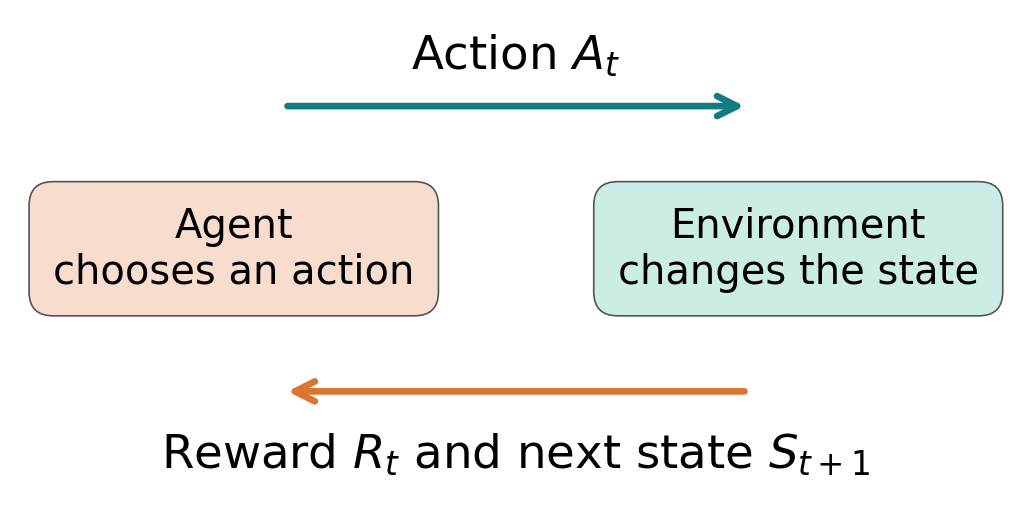

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axis("off")
for x, label, color in [(.22, "Agent\nchooses an action", "#f8ddce"),
                        (.78, "Environment\nchanges the state", "#ccece6")]:
    ax.text(x, .5, label, ha="center", va="center", fontsize=24,
            bbox=dict(boxstyle="round,pad=.6", fc=color, ec="#555555"))
ax.annotate("", xy=(.73, .8), xytext=(.27, .8),
            arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=30, color=COLORS[0]))
ax.text(.5, .88, r"Action $A_t$", ha="center", fontsize=28)
ax.annotate("", xy=(.27, .2), xytext=(.73, .2),
            arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=30, color=COLORS[1]))
ax.text(.5, .04, r"Reward $R_t$ and next state $S_{t+1}$", ha="center", fontsize=28)
ax.set(xlim=(0, 1), ylim=(-.06, 1))
plt.tight_layout()
plt.show()

図 2：エージェントが決めるのは行動であり、その結果としてどこへ移るか、何点を得るかは環境が決める。行動選択に乱数を使う場合も、移動結果に乱数が入る場合もある。この 2 種類の不確実さは、次節で別々に表す。

> **2.1 のまとめ**
>
> - MDP では、行動が次の状態に影響する。
> - 状態は今の状況、行動は選択、報酬はその結果の評価を表す。
> - 環境とのやりとりを繰り返すと、状態・行動・報酬の列ができる。

# 2.2 環境とエージェントの定式化

ここからは有限個の状態と行動を考える。状態の集合を $\mathcal{S}$、行動の集合を $\mathcal{A}$ と書く。

| 担当 | 数式 | 決めるもの |
|---|---|---|
| 環境 | $p(s'\mid s,a)$ | 次にどこへ移るか |
| 環境 | $r(s,a,s')$ | その移動でどの報酬を返すか |
| エージェント | $\pi(a\mid s)$ | 今の状態で何をするか |

これらを分けておくと、同じ環境で方策だけを変えたり、同じ方策で移動の不確実さだけを変えたりできる。

## 2.2.1 状態遷移

状態 $s$ で行動 $a$ を選んだとき、次の状態が $s'$ になる確率を**状態遷移確率**という。

$$p(s'\mid s,a)=P(S_{t+1}=s'\mid S_t=s,A_t=a).$$

縦棒の右側は条件、左側は確率を求めたい結果である。$s'$ のプライムは微分ではなく、「次の状態」を区別する印である。

固定した $(s,a)$ ごとに、次の条件が成り立つ。

$$
p(s'\mid s,a)\ge0,\qquad
\sum_{s'\in\mathcal{S}}p(s'\mid s,a)=1.
$$

和を取るのは**次状態 $s'$**についてである。出発点 $s$ や選んだ行動 $a$ まで同時に足すわけではない。

### マルコフ性：過去の情報を、現在の状態にまとめる

次の状態の分布が、現在の状態と行動によって決まり、それ以前の履歴を追加しても変わらない性質を**マルコフ性**という。

$$
P(S_{t+1}=s'\mid S_0,A_0,R_0,\ldots,S_t=s,A_t=a)
=P(S_{t+1}=s'\mid S_t=s,A_t=a).
$$

今回の固定されたグリッドでは、同じマスから同じ行動をすれば、そこまでの経路によらず同じ規則で移動する。現在位置だけで、この性質を満たせる。

**マルコフ性は、次状態が一意に決まることではない。** 次状態が確率的でも、その確率分布が現在の状態と行動で定まればよい。また、$p$ に時刻 $t$ を付けないのは、ここで環境の規則が時間によって変わらないと仮定しているためである。

MDP として扱うには、報酬についても、現在の状態・行動とその遷移で結果を説明できる必要がある。今回の報酬は移動先だけで決まるので、この条件も満たす。

### 状態に必要な情報が足りない場合

鍵を持っているときだけ、右隣の扉を通れる環境を考える。

| 現在位置 | 過去の経路で鍵を拾ったか | RIGHT の結果 |
|---|---|---|
| 扉の左 | はい | 扉の先へ移動 |
| 扉の左 | いいえ | その場にとどまる |

現在位置だけを状態にすると、同じ状態・行動なのに、鍵を拾った履歴で結果が変わってしまう。`(現在位置, 鍵の有無)` を状態に含めれば、この違いを表せる。

「現在だけ見ればよい」と決めつけるのではなく、**未来の結果を説明するための情報を状態に含める**ことが大切である。観測した情報が、そのまま十分な状態になるとは限らない。

### 決定的な状態遷移

次状態が 1 つに決まる場合、その規則を $s'=f(s,a)$ と書ける。確率で表すなら、行き先の確率が 1、それ以外は 0 になる。

$$
p(s'\mid s,a)=
\begin{cases}
1 & (s'=f(s,a)),\\
0 & (\text{それ以外}).
\end{cases}
$$

まず、壁と盤面の端を考慮した関数を作る。ゴールでは実際のやりとりを止めるが、後の確率表を全状態で定義するため、関数上はゴールからゴールへとどまるものとする。

In [4]:
def next_state(state, action):
    if state == GOAL:
        return GOAL
    dy, dx = MOVES[action]
    candidate = (state[0] + dy, state[1] + dx)
    row, col = candidate
    if not (0 <= row < HEIGHT and 0 <= col < WIDTH) or candidate == WALL:
        return state
    return candidate

examples = [((2, 0), 0), ((1, 0), 3), ((2, 0), 2), ((0, 2), 3)]
display(pd.DataFrame([
    {"状態 s": s, "行動 a": ACTION_NAMES[a], "次状態 f(s,a)": next_state(s, a)}
    for s, a in examples
]))
assert next_state((1, 0), 3) == (1, 0)  # 壁
assert next_state((2, 0), 2) == (2, 0)  # 盤面の外
assert next_state((0, 2), 3) == GOAL

,状態 s,行動 a,"次状態 f(s,a)"
0,"(2, 0)",UP,"(1, 0)"
1,"(1, 0)",RIGHT,"(1, 0)"
2,"(2, 0)",LEFT,"(2, 0)"
3,"(0, 2)",RIGHT,"(0, 3)"


2 行目と 3 行目では、行動を選んでも位置が変わらない。**その場にとどまることも、状態遷移の 1 つ**である。無効な移動先を確率の計算から捨てるのではなく、その確率を現在位置への遷移に割り当てる。

### 確率的な状態遷移

追加実験として、床が滑る環境を考える。意図した方向へ進む確率を $0.8$、それに直交する 2 方向へ進む確率をそれぞれ $0.1$ とする。たとえば `RIGHT` を選んだ場合は、右へ $0.8$、上へ $0.1$、下へ $0.1$ となる。

壁や盤面の外に当たる場合は、ずれた方向も含めてその場にとどまる。複数の移動方向が同じ次状態になる場合、その確率を足し合わせる。

コードの `slip` は「直交する方向へずれる確率の**合計**」である。`slip=0.2` なら各方向が $0.1$、`slip=0` なら先ほどの決定的な環境になる。

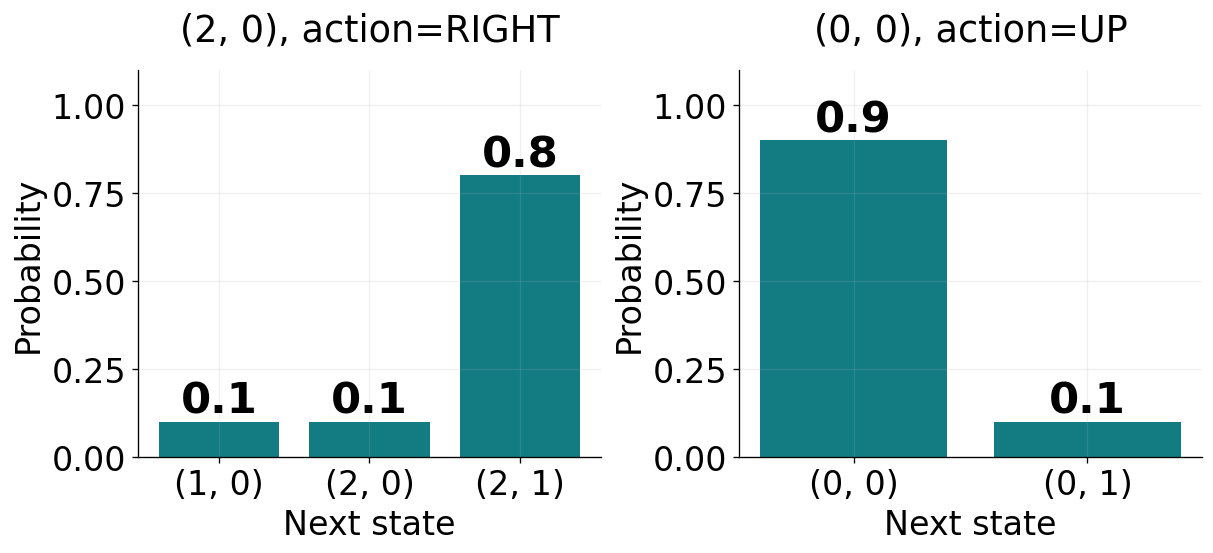

In [5]:
SIDE_ACTIONS = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}

def transition_probs(state, action, slip=0.0):
    if not 0 <= slip <= 1:
        raise ValueError("slip must be between 0 and 1")
    probs = np.zeros(len(STATES))
    side1, side2 = SIDE_ACTIONS[action]
    for direction, probability in [(action, 1 - slip),
                                   (side1, slip / 2), (side2, slip / 2)]:
        destination = next_state(state, direction)
        probs[STATE_INDEX[destination]] += probability  # 同じ行き先の確率を合算
    return probs

# どの状態・行動でも、次状態についての確率の和は 1。
for slip in [0.0, 0.2, 1.0]:
    for state in STATES:
        for action in range(4):
            probs = transition_probs(state, action, slip)
            assert np.all(probs >= 0) and np.isclose(probs.sum(), 1)

# 元の横並びを保ち、文字を拡大した分の余白を確保する。
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
for ax, (state, action) in zip(axes, [(START, 3), ((0, 0), 0)]):
    probs = transition_probs(state, action, slip=0.2)
    indices = np.flatnonzero(probs)
    ax.bar([str(STATES[i]) for i in indices], probs[indices], color=COLORS[0])
    ax.set(title=f"{state}, action={ACTION_NAMES[action]}",
           xlabel="Next state", ylabel="Probability", ylim=(0, 1.10))
    for x, i in enumerate(indices):
        ax.text(x, probs[i] + .025, f"{probs[i]:.1f}", ha="center",
                fontsize=26, fontweight="bold")
plt.show()

図 3：左は左下で `RIGHT` を選んだ場合で、右へ $0.8$、上へ $0.1$、その場に $0.1$ となる。下へのずれは盤面の外なので、その場にとどまる。

右は左上で `UP` を選んだ場合である。上へ進もうとする $0.8$ と、左へずれる $0.1$ が、どちらも現在位置に戻る。したがって $p((0,0)\mid(0,0),\mathrm{UP})=0.9$ となり、右へ進む確率だけが $0.1$ になる。

### 確率と、観測した頻度を比べる

同じ状態 `(2, 0)`、同じ行動 `RIGHT` を条件として、次状態を 10,000 回抽選する。ここでは毎回同じ出発点に戻しており、1 本の経路を進み続ける実験ではない。

In [6]:
rng = np.random.default_rng(SEED)
draws = 10_000
probs = transition_probs(START, 3, slip=0.2)
samples = rng.choice(len(STATES), size=draws, p=probs)
frequencies = np.bincount(samples, minlength=len(STATES)) / draws
indices = np.flatnonzero(probs)
display(pd.DataFrame({
    "次状態": [STATES[i] for i in indices],
    "理論上の確率": probs[indices],
    "観測した頻度": frequencies[indices],
    "頻度 - 確率": (frequencies - probs)[indices],
}).round(4))

,次状態,理論上の確率,観測した頻度,頻度 - 確率
0,"(1, 0)",0.1,0.1014,0.0014
1,"(2, 0)",0.1,0.1022,0.0022
2,"(2, 1)",0.8,0.7964,-0.0036


観測した頻度は理論上の確率に近づくが、有限回では完全に一致するとは限らない。状態遷移確率は環境の規則であり、観測頻度は得られたデータから計算する値である。前章で区別した「真の勝率」と「当たりの割合」と同じ関係になっている。

## 2.2.2 報酬関数

状態 $s$ で行動 $a$ を選び、次の状態が $s'$ になったときの報酬を $r(s,a,s')$ と書く。今回のグリッドでは、実際に着いたマスによって次のように決める。

$$
r(s,a,s')=
\begin{cases}
0 & (s=\mathrm{Goal}),\\
+1 & (s\ne\mathrm{Goal},\ s'=\mathrm{Goal}),\\
-1 & (s\ne\mathrm{Goal},\ s'=\mathrm{Penalty}),\\
0 & (\text{それ以外}).
\end{cases}
$$

最初の行は、ゴールにとどまるとした計算上の扱いに対応する。**ゴールに入るときに 1 回だけ $+1$ を得て、その後は報酬を受け取らない**。

この例では報酬は主に $s'$ で決まるが、一般には移動元 $s$ や行動 $a$ にも依存してよい。たとえば、燃料を多く使う行動に負の報酬を設定する場合である。ここでは遷移が決まれば報酬も決まるものとする。

In [7]:
def reward(state, action, s_next):
    if state == GOAL:
        return 0.0
    if s_next == GOAL:
        return 1.0
    if s_next == PENALTY:
        return -1.0
    return 0.0

reward_examples = [((0, 2), 3), ((1, 2), 3), ((2, 0), 0), ((1, 3), 3)]
display(pd.DataFrame([
    {"状態 s": s, "行動 a": ACTION_NAMES[a], "次状態 s'": next_state(s, a),
     "報酬 r(s,a,s')": reward(s, a, next_state(s, a))}
    for s, a in reward_examples
]))
assert reward((0, 2), 3, GOAL) == 1.0
assert reward(GOAL, 3, GOAL) == 0.0

,状態 s,行動 a,次状態 s',"報酬 r(s,a,s')"
0,"(0, 2)",RIGHT,"(0, 3)",1.0
1,"(1, 2)",RIGHT,"(1, 3)",-1.0
2,"(2, 0)",UP,"(1, 0)",0.0
3,"(1, 3)",RIGHT,"(1, 3)",-1.0


最後の行は `Penalty` で右の外壁へ向かった場合である。その場にとどまっても、移動先は再び `Penalty` なので $-1$ を得る。このルールは [`GridWorld.reward`](../common/gridworld.py) の「移動先のマスで報酬を決める」という実装に対応する。

報酬は、エージェントが満足したかどうかで後から変えるものではなく、環境で定めた数値である。また、**即時報酬と、将来も含めた行動の価値は異なる**。通常のマスでは、良い方向へ進んでも即時報酬は 0 になる。

### 次状態が確率的な場合の、報酬の期待値

ゴールの左 `(0, 2)` から `RIGHT` を選んでも、床が滑る場合は必ず $+1$ を得るわけではない。次状態ごとの報酬を、その次状態に移る確率で重み付けする。

$$
\begin{aligned}
\bar r(s,a)
&=\mathbb{E}[R_t\mid S_t=s,A_t=a]\\
&=\sum_{s'}p(s'\mid s,a)\,r(s,a,s').
\end{aligned}
$$

この資料では、遷移ごとの報酬関数と区別するため、次状態について平均した報酬を $\bar r(s,a)$ と表す。$r(s,a)$ と書く場合もあるので、何について平均した記号かを確認する。

In [8]:
state, action = (0, 2), 3
probs = transition_probs(state, action, slip=0.2)
rewards = np.array([reward(state, action, s_next) for s_next in STATES])
indices = np.flatnonzero(probs)
display(pd.DataFrame({
    "次状態 s'": [STATES[i] for i in indices],
    "p(s'|s,a)": probs[indices],
    "r(s,a,s')": rewards[indices],
    "確率 × 報酬": (probs * rewards)[indices],
}))
expected_reward = probs @ rewards  # 要素ごとの積を足す
print(f"RIGHT を選んだ 1 ステップの期待報酬: {expected_reward:.3f}")
assert np.isclose(expected_reward, 0.8)

,次状態 s',"p(s'|s,a)","r(s,a,s')",確率 × 報酬
0,"(0, 2)",0.1,0.0,0.0
1,"(0, 3)",0.8,1.0,0.8
2,"(1, 2)",0.1,0.0,0.0


RIGHT を選んだ 1 ステップの期待報酬: 0.800


ゴールへ移る確率 $0.8$ のときだけ $+1$ なので、期待報酬は $0.8$ になる。**1 回の試行で報酬 $0.8$ が返るわけではない**。返るのは、この場合は $0$ または $1$ である。

なお、報酬自体が確率的なモデルも考えられる。その場合は、$r(s,a,s')$ をその遷移における条件付き期待報酬と定義すれば、同じ期待値の式を使える。この資料の実験では、報酬自体の追加の乱数は使わない。

### 1 ステップごとの中身を追う

まずは行動列を手で指定し、決定的な環境で状態と報酬を確認する。上へ進んだ直後に右を選ぶと、壁にぶつかって同じ位置にとどまる。その後は上の通路を右へ進む。

In [9]:
scripted_actions = [0, 3, 0, 3, 3, 3]  # UP, RIGHT, UP, RIGHT, RIGHT, RIGHT
state = START
trace = []
for t, action in enumerate(scripted_actions):
    s_next = next_state(state, action)
    r_t = reward(state, action, s_next)
    trace.append({"t": t, "S_t": state, "A_t": ACTION_NAMES[action],
                  "R_t": r_t, "S_(t+1)": s_next, "ゴール到達": s_next == GOAL})
    state = s_next
    if state == GOAL:
        break
display(pd.DataFrame(trace))
assert state == GOAL and len(trace) == 6
assert sum(row["R_t"] for row in trace) == 1.0

,t,S_t,A_t,R_t,S_(t+1),ゴール到達
0,0,"(2, 0)",UP,0.0,"(1, 0)",False
1,1,"(1, 0)",RIGHT,0.0,"(1, 0)",False
2,2,"(1, 0)",UP,0.0,"(0, 0)",False
3,3,"(0, 0)",RIGHT,0.0,"(0, 1)",False
4,4,"(0, 1)",RIGHT,0.0,"(0, 2)",False
5,5,"(0, 2)",RIGHT,1.0,"(0, 3)",True


各行の `S_(t+1)` が、次の行の `S_t` になっている。`t=1` では右を選んでも壁で動けず、報酬は 0 のままである。最後の行だけ、ゴールへの移動に対して $+1$ を得る。

ここまでのコードは、環境を調べるために行動を手で並べたものだった。次は、「今の状態を見て、どの行動を選ぶか」という規則を用意する。

## 2.2.3 エージェントの方策

エージェントが状態に応じて行動を選ぶ規則を**方策（policy）**という。

**決定的方策**では、状態 $s$ に対して行動が 1 つに決まる。

$$a=\mu(s).$$

**確率的方策**では、状態ごとに各行動を選ぶ確率を与える。

$$\pi(a\mid s)=P(A_t=a\mid S_t=s).$$

固定した状態 $s$ に対して、

$$\pi(a\mid s)\ge0,\qquad\sum_{a\in\mathcal{A}}\pi(a\mid s)=1.$$

こちらは**行動 $a$**について和を取る。状態遷移確率では、状態と行動を固定して次状態について足した。条件と、和を取る対象の違いに注意する。

決定的方策も、選ぶ行動の確率を 1、それ以外を 0 とすれば、$\pi(a\mid s)$ で表せる。以下では、状態ごとに同じ規則を使い続ける方策を扱う。

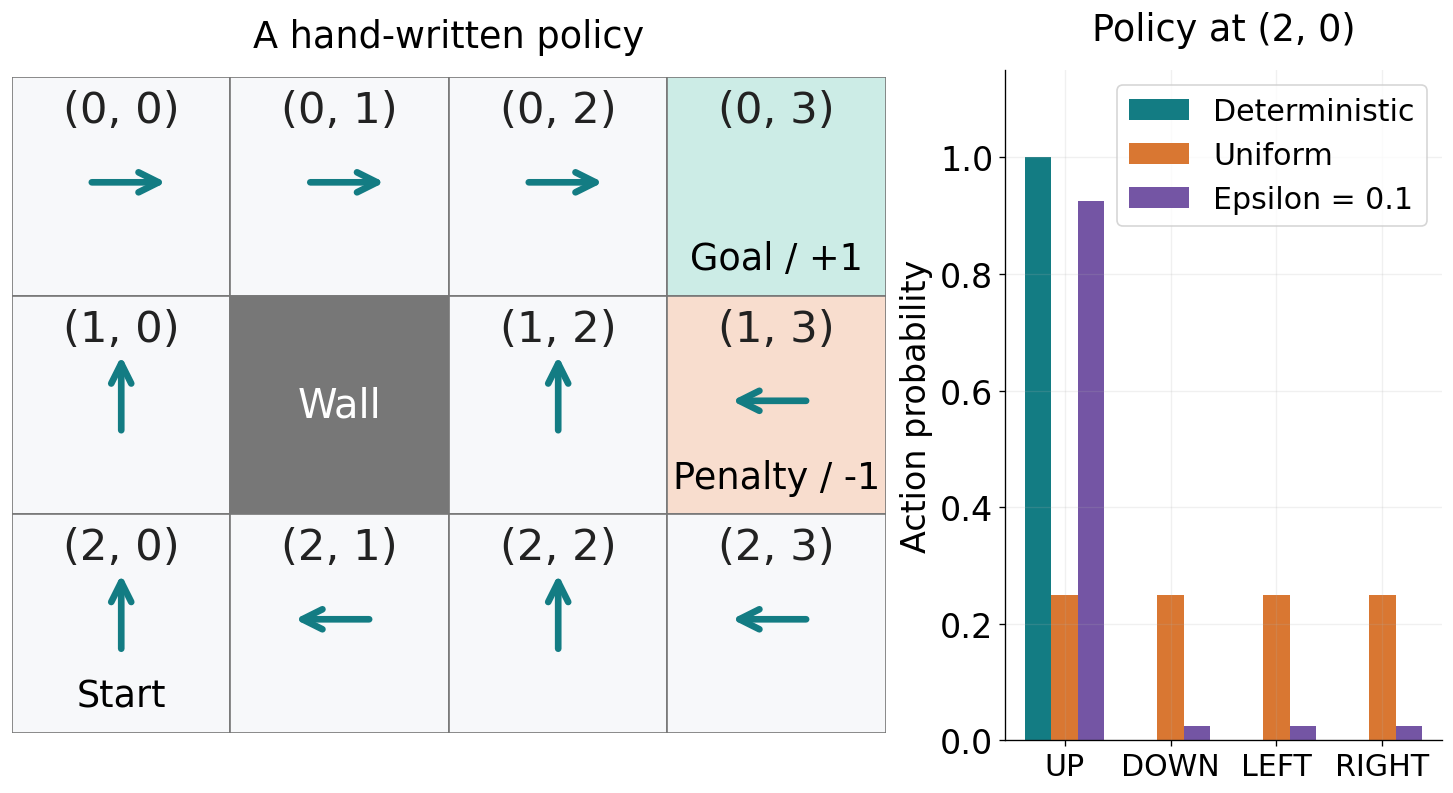

In [10]:
# 説明用に人が決めた方策。ゴールでは行動を選ばない。
chosen_actions = {
    (0, 0): 3, (0, 1): 3, (0, 2): 3,
    (1, 0): 0,            (1, 2): 0, (1, 3): 2,
    (2, 0): 0, (2, 1): 2, (2, 2): 0, (2, 3): 2,
}
pi_deterministic = {s: np.eye(4)[chosen_actions[s]] for s in ACTIVE_STATES}
pi_uniform = {s: np.full(4, 0.25) for s in ACTIVE_STATES}

epsilon = 0.1
pi_epsilon = {}
for state in ACTIVE_STATES:
    probabilities = np.full(4, epsilon / 4)
    probabilities[chosen_actions[state]] += 1 - epsilon
    pi_epsilon[state] = probabilities

for policy in [pi_deterministic, pi_uniform, pi_epsilon]:
    assert set(policy) == set(ACTIVE_STATES)
    for probabilities in policy.values():
        assert np.all(probabilities >= 0) and np.isclose(probabilities.sum(), 1)

# 横並びのまま、長いラベルを含むグリッド側に幅を確保する。
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2, 1]})
draw_grid(axes[0], "A hand-written policy", chosen_actions)
x = np.arange(4)
for offset, (name, policy) in zip([-.25, 0, .25], [
    ("Deterministic", pi_deterministic), ("Uniform", pi_uniform),
    ("Epsilon = 0.1", pi_epsilon),
]):
    axes[1].bar(x + offset, policy[START], width=.25, label=name)
axes[1].set(xticks=x, xticklabels=ACTION_NAMES, ylim=(0, 1.15),
            ylabel="Action probability", title=f"Policy at {START}")
axes[1].tick_params(axis="x", labelsize=18)
axes[1].legend(loc="upper right", fontsize=18)
plt.show()

図 4：左は各マスで選ぶ行動を矢印で示している。これは手で用意した方策であり、学習して得た結果ではない。右はスタート地点での行動確率である。決定的方策では上へ必ず進もうとし、一様ランダム方策では 4 方向をそれぞれ $0.25$ で選ぶ。

第 1 章の $\varepsilon$-greedy 法と同じ確率の混ぜ方も使える。優先する行動が 1 つなら、

$$
\pi(a\mid s)=
\begin{cases}
1-\varepsilon+\varepsilon/4 & (a=\mu(s)),\\
\varepsilon/4 & (a\ne\mu(s)).
\end{cases}
$$

$\varepsilon=0.1$ では、優先する行動の確率は $0.925$、他の 3 行動はそれぞれ $0.025$ になる。探索でも優先する行動を選ぶ可能性があるため、$0.9$ ではない。ここでの優先行動は手で指定しており、行動価値を学習する実装はまだ行っていない。

### 方策の確率と、環境の確率は別のもの

たとえば、スタートで必ず `UP` を選ぶ方策でも、床が滑れば別の方向へ進むことがある。反対に、床が滑らなくても、方策が一様ランダムなら選ぶ行動自体が毎回変わる。

| 方策 | 環境の遷移 | 同じ状態からの 1 ステップ |
|---|---|---|
| 決定的 | 決定的 | 同じ行動を選び、同じ次状態へ移る |
| 確率的 | 決定的 | 行動を抽選し、その行動の行き先へ移る |
| 決定的 | 確率的 | 同じ行動を選び、次状態を抽選する |
| 確率的 | 確率的 | 行動と、その結果の次状態を順に抽選する |

次のコードでは、**方策で行動を選ぶ → 環境で次状態を選ぶ → 報酬を受け取る**という順序を、そのまま実装する。

In [11]:
def run_trajectory(policy, slip=0.0, seed=SEED, max_steps=30):
    # 行動選択と環境の乱数を分けて、どちらを抽選しているか明確にする。
    rng_action = np.random.default_rng(seed)
    rng_env = np.random.default_rng(seed + 1)
    state = START
    records = []
    for t in range(max_steps):
        action = int(rng_action.choice(4, p=policy[state]))
        probs = transition_probs(state, action, slip=slip)
        s_next = STATES[int(rng_env.choice(len(STATES), p=probs))]
        r_t = reward(state, action, s_next)
        records.append({"t": t, "S_t": state, "A_t": ACTION_NAMES[action],
                        "R_t": r_t, "S_(t+1)": s_next})
        state = s_next
        if state == GOAL:
            break
    # 観察の上限に達した場合と、環境のゴールに到達した場合を区別する。
    return pd.DataFrame(records), state == GOAL

fixed_trace, fixed_goal = run_trajectory(pi_deterministic, slip=0.0)
random_trace, random_goal = run_trajectory(pi_epsilon, slip=0.2)
print("確率的方策 × 確率的環境の履歴（先頭 12 ステップ）")
display(random_trace.head(12))
display(pd.DataFrame([
    {"設定": "決定的方策 × 決定的環境", "ステップ数": len(fixed_trace),
     "報酬の合計": fixed_trace["R_t"].sum(), "停止理由": "ゴール" if fixed_goal else "観察上限"},
    {"設定": "確率的方策 × 確率的環境", "ステップ数": len(random_trace),
     "報酬の合計": random_trace["R_t"].sum(), "停止理由": "ゴール" if random_goal else "観察上限"},
]))
assert fixed_goal and len(fixed_trace) == 5

確率的方策 × 確率的環境の履歴（先頭 12 ステップ）


,t,S_t,A_t,R_t,S_(t+1)
0,0,"(2, 0)",UP,0.0,"(2, 1)"
1,1,"(2, 1)",LEFT,0.0,"(2, 0)"
2,2,"(2, 0)",UP,0.0,"(2, 1)"
3,3,"(2, 1)",LEFT,0.0,"(2, 0)"
4,4,"(2, 0)",UP,0.0,"(1, 0)"
5,5,"(1, 0)",UP,0.0,"(0, 0)"
6,6,"(0, 0)",RIGHT,0.0,"(0, 1)"
7,7,"(0, 1)",RIGHT,0.0,"(0, 2)"
8,8,"(0, 2)",RIGHT,0.0,"(1, 2)"
9,9,"(1, 2)",UP,0.0,"(0, 2)"


,設定,ステップ数,報酬の合計,停止理由
0,決定的方策 × 決定的環境,5,1.0,ゴール
1,確率的方策 × 確率的環境,11,1.0,ゴール


決定的な組合せでは、上へ 2 回、右へ 3 回の計 5 ステップでゴールに着く。確率的な組合せでは、行動選択や移動結果の抽選によって経路が変わる。上限の 30 ステップで止まった場合は、ゴールに着いたことにはならない。

この実験では方策を更新していない。環境と方策を組み合わせて「経験の列を生成する仕組み」を確かめている。1 回の経路だけで、方策の平均的な成績や最適性は判断できない。

## 2.1〜2.2 のまとめ

| 確認したいこと | 使うもの | 固定するもの | 和を取る対象 |
|---|---|---|---|
| 次にどこへ移るか | $p(s'\mid s,a)$ | 状態 $s$ と行動 $a$ | 次状態 $s'$：合計 1 |
| 遷移で何点を得るか | $r(s,a,s')$ | 状態・行動・次状態 | 確率ではないので、合計 1 の条件はない |
| どの行動を選ぶか | $\pi(a\mid s)$ | 状態 $s$ | 行動 $a$：合計 1 |

- マルコフ性は、現在の状態と行動が分かれば、次の結果の分布を説明するのに過去の履歴を必要としない性質である。
- 決定的か確率的かは、環境と方策それぞれについて考える。
- 観測した 1 回の報酬と、その期待値、将来まで含めた価値を区別する。
- 今回実装したのは、環境の規則と、与えた方策によるやりとりである。

次の 2.3 では、将来の報酬をどのようにまとめるかを定め、状態の価値と最適な方策を考える。今回の $p$・$r$・$\pi$ は、そのための土台になる。

## 確認問題

1. 前章の非定常バンディットと、今回のグリッドワールドは、何が変化する点で異なるか。
2. 左上 `(0, 0)` で `UP` を選び、`slip=0.2` とする。可能な次状態と、それぞれの確率を求めよ。
3. 「同じ状態・行動でも次状態がランダムに変わる環境は、マルコフ性を満たさない」は正しいか。
4. ゴールの左 `(0, 2)` で `RIGHT` を選び、`slip=0.2` とする。期待報酬と、1 回に得られる報酬を答えよ。
5. 4 行動のうち優先する行動が 1 つあるとき、$\varepsilon=0.2$ で各行動を選ぶ確率はいくつか。
6. $\sum_{s'}p(s'\mid s,a)=1$ と $\sum_a\pi(a\mid s)=1$ は、それぞれ何を固定しているか。
7. あるマスに「初めて訪れたときだけ $+1$」を与える場合、現在位置だけで報酬を説明できるか。

コードで試す場合は、`slip` を `0.0`、`0.2`、`1.0` に変えて図 3 を比べる。また、`run_trajectory` の方策を `pi_uniform` に変え、ゴールに着く前に観察上限へ達する場合があることを確かめる。

<details>
<summary>解答例（クリックして開く）</summary>

1. 非定常バンディットでは、ここまでの設定では行動と無関係に各腕の勝率が変化した。グリッドワールドでは、選んだ行動によって現在位置が変わる。今回の移動規則自体は固定されている。
2. `(0, 0)` が $0.9$、`(0, 1)` が $0.1$。上への $0.8$ と左への $0.1$ は、どちらも盤面の外に向かうので現在位置に合算する。
3. 正しくない。現在の状態と行動を条件にすれば過去の履歴を加えても次状態の分布が変わらないことが、マルコフ性の条件である。一意に決まる必要はない。
4. 期待報酬は $0.8$。1 回の報酬は、ゴールに着けば $1$、それ以外は $0$。
5. 優先する行動は $1-0.2+0.2/4=0.85$。他の 3 行動はそれぞれ $0.2/4=0.05$。
6. 状態遷移では状態 $s$ と行動 $a$ を固定して次状態について足す。方策では状態 $s$ を固定して行動について足す。
7. 説明できない。過去に訪れたかどうかで報酬が変わるため、たとえば状態に訪問済みマスの集合を含める必要がある。位置の移動規則がマルコフ的でも、報酬を説明する情報が不足する場合がある。

</details>

## 付録 A. 方策と状態遷移を組み合わせた 1 ステップ

状態 $s$ から、行動 $a$ を選んで次状態 $s'$ へ進む確率は、条件付き確率の積で求められる。

$$
P(A_t=a,S_{t+1}=s'\mid S_t=s)
=\pi(a\mid s)\,p(s'\mid s,a).
$$

先に方策で行動を選び、その選んだ行動を条件に環境が次状態を返す。行動と次状態を独立と仮定した積ではない。

どの行動を選んだかを区別せず、次状態だけの確率を知りたい場合は、行動について足す。

$$p_\pi(s'\mid s)=\sum_a\pi(a\mid s)\,p(s'\mid s,a).$$

同じ考え方で、状態 $s$ からの **1 ステップだけ**の期待報酬は、

$$\mathbb{E}_\pi[R_t\mid S_t=s]
=\sum_a\pi(a\mid s)\sum_{s'}p(s'\mid s,a)\,r(s,a,s').$$

この式には、次の時刻以降の報酬はまだ含まれていない。

In [12]:
state = (0, 2)
policy_probs = pi_epsilon[state]
# 行が行動、列が次状態。P[a, i] = p(STATES[i] | state, a)
P = np.array([transition_probs(state, a, slip=0.2) for a in range(4)])
R = np.array([[reward(state, a, s_next) for s_next in STATES] for a in range(4)])
joint = policy_probs[:, None] * P
next_probs = joint.sum(axis=0)  # 行動について足し合わせる
one_step_reward = np.sum(joint * R)

assert P.shape == (4, 11)
assert np.allclose(P.sum(axis=1), 1)
assert np.isclose(joint.sum(), 1) and np.isclose(next_probs.sum(), 1)
indices = np.flatnonzero(next_probs)
joint_table = pd.DataFrame(joint[:, indices], index=ACTION_NAMES,
                           columns=[str(STATES[i]) for i in indices])
joint_table.loc["Next-state probability"] = next_probs[indices]
display(joint_table.round(4))
print(f"方策と環境の両方を平均した 1 ステップの期待報酬: {one_step_reward:.3f}")
assert np.isclose(one_step_reward, 0.745)

,"(0, 1)","(0, 2)","(0, 3)","(1, 2)"
UP,0.0025,0.0200,0.0025,0.0000
DOWN,0.0025,0.0000,0.0025,0.0200
LEFT,0.0200,0.0025,0.0000,0.0025
RIGHT,0.0000,0.0925,0.7400,0.0925
Next-state probability,0.0250,0.1150,0.7450,0.1150


方策と環境の両方を平均した 1 ステップの期待報酬: 0.745


表の各要素は「その行動を選び、かつその次状態に着く確率」である。各行の和は、その行動を選ぶ確率 $\pi(a\mid s)$ になる。最下行は、行動について足した次状態の分布である。

この状態では、ゴールに到達するときだけ報酬 $+1$ を得る。`RIGHT` を選んで右へ進む場合に加え、`UP` や `DOWN` を選んで右へずれる場合もある。

$$0.925\times0.8+0.025\times0.1+0.025\times0.1=0.745.$$

「`RIGHT` を選んだ」という条件付きの期待報酬 $0.8$ と、方策による行動選択も平均した期待報酬 $0.745$ は、平均する対象が異なる。